# Çelik Üretim Tesisinde Kısa Vadeli Enerji Tüketimi Tahmini
**Rana Beyza Culus · Endüstri Mühendisi**  
Yapay Zekâ İçin Basitleştirilmiş Python · Final projesi

## 1. Problem ve kapsam
Son tamamlanmış 15 ve 30 dakikalık tüketim, geçmiş bir saatlik ortalama, saat ve hafta sonu bilgisiyle **bir sonraki 15 dakikalık dönemin enerji tüketimini (kWh)** tahmin ediyoruz. Bu bir regresyon problemidir. Kısa vadeli tahmin, üretim tesisinde enerji talebinin izlenmesine ve planlama kararlarının desteklenmesine yardımcı olabilir. Bu çalışma tasarruf veya emisyon azalması ölçmez.

**Çalıştırma:** Colab'da bu defteri açın ve ilk hücreden başlayarak çalıştırın. CSV aynı klasörde yoksa resmi kaynaktan otomatik indirilir. İnternet erişimi yoksa `Steel_industry_data.csv` dosyasını Colab'ın Dosyalar bölümüne yükleyin. Son hücre etkileşimli tahmin ister.

**Kaynak:** Sathishkumar V E, Shin ve Cho (2021), UCI Steel Industry Energy Consumption, DOI: https://doi.org/10.24432/C52G8C · CC BY 4.0. https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption


In [1]:
import io, zipfile, urllib.request, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#087E8B','#D45D35','#17324D'])
print('Python:', sys.version.split()[0], 'Pandas:', pd.__version__, 'scikit-learn:', sklearn.__version__)
csv_path = Path('Steel_industry_data.csv')
if not csv_path.exists():
    url = 'https://archive.ics.uci.edu/static/public/851/steel+industry+energy+consumption.zip'
    with urllib.request.urlopen(url, timeout=60) as r:
        with zipfile.ZipFile(io.BytesIO(r.read())) as z:
            csv_path.write_bytes(z.read('Steel_industry_data.csv'))
raw = pd.read_csv(csv_path)
display(raw.head())
print('Boyut:', raw.shape)


Python: 3.12.14 Pandas: 2.2.3 scikit-learn: 1.8.0
Boyut: (35040, 11)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


## 2. Veri sözlüğü ve kalite kontrolü
Veri, Güney Kore'deki bir çelik tesisinden 2018 yılı boyunca toplanan 15 dakikalık kayıtlardır. Ham veriyi koruyoruz. Hedef dışındaki elektriksel ölçümler aynı döneme ait olduğundan gelecekteki tüketimin tahmininde kullanılmıyor.

| Ham sütun | Tür | Anlam / kullanım |
|---|---|---|
| date | Tarih metni | Kayıt zamanı, zaman özellikleri için |
| Usage_kWh | Sayısal | 15 dakikalık enerji tüketimi, hedef |
| Lagging_Current_Reactive.Power_kVarh | Sayısal | Gecikmeli reaktif enerji, model dışında |
| Leading_Current_Reactive_Power_kVarh | Sayısal | İlerlemeli reaktif enerji, model dışında |
| CO2(tCO2) | Sayısal | Kaynakta CO₂ göstergesi, model dışında |
| Lagging_Current_Power_Factor | Sayısal | Gecikmeli güç faktörü (%), model dışında |
| Leading_Current_Power_Factor | Sayısal | İlerlemeli güç faktörü (%), model dışında |
| NSM | Sayısal | Gece yarısından itibaren saniye, kontrol için |
| WeekStatus | Kategorik | Hafta içi / sonu etiketi, kontrol için |
| Day_of_week | Kategorik | Kaynaktaki gün etiketi, model dışında |
| Load_Type | Kategorik | Yük sınıfı, model dışında |

**Zaman varsayımı:** Dosyanın özgün satır düzeninde her gün 00:15 ile başlayıp aynı tarihli 00:00 ile biter. Bu son kayıtları gün sonu kabul ederek tarihlerine bir gün ekliyoruz. Bu bir kaynak yazım biçimi yorumudur. Dönüşümden sonra tüm aralıkların 15 dakika olmasını doğruluyoruz. Kaynak etiketleri yerine takvim özelliklerini düzeltilmiş zamandan hesaplıyoruz.


In [2]:
quality = pd.Series({'satir':len(raw), 'sutun':raw.shape[1],
    'eksik_hucre':int(raw.isna().sum().sum()), 'tam_kopya':int(raw.duplicated().sum()),
    'negatif_tuketim':int(raw.Usage_kWh.lt(0).sum())})
display(quality.to_frame('Sonuç'))
assert raw.isna().sum().sum() == 0, 'Eksik veri var, temizleme kararını gözden geçirin.'
assert not raw.duplicated().any() and not raw.Usage_kWh.lt(0).any()
df = raw.copy()
parsed = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M', errors='raise')
midnight = parsed.dt.hour.eq(0) & parsed.dt.minute.eq(0)
df['zaman'] = parsed + pd.to_timedelta(midnight.astype(int), unit='d')
df = df.sort_values('zaman').reset_index(drop=True)
assert not df.zaman.duplicated().any()
assert df.zaman.diff().dropna().eq(pd.Timedelta(minutes=15)).all()
print('Gün sonu kabul edilen kayıt:', int(midnight.sum()))
print('Düzeltilmiş zaman aralığı:', df.zaman.min(), '-', df.zaman.max())
display(df[['Usage_kWh']].describe())
display(df['Load_Type'].value_counts().to_frame('Kayıt'))


Gün sonu kabul edilen kayıt: 365
Düzeltilmiş zaman aralığı: 2018-01-01 00:15:00 - 2019-01-01 00:00:00


,Sonuç
satir,35040
sutun,11
eksik_hucre,0
tam_kopya,0
negatif_tuketim,0


,Usage_kWh
count,35040.000000
mean,27.386892
std,33.444380
min,0.000000
25%,3.200000
50%,4.570000
75%,51.237500
max,157.180000


,Kayıt
Load_Type,
Light_Load,18072
Medium_Load,9696
Maximum_Load,7272


## 3. Özellikler ve kronolojik veri ayrımı
Her hedef dönemi için yalnızca o dönem başlamadan bilinen tüketim değerlerini kullanıyoruz. `shift(1).rolling(4)` mevcut hedefi ortalamaya katmaz. İlk dört kayıtta geçmiş yetersiz olduğundan bu kayıtlar çıkarılır.

| Özellik | Tür | Açıklama |
|---|---|---|
| tuketim_15dk_once | Sayısal | Bir önceki dönemin kWh değeri |
| tuketim_30dk_once | Sayısal | İki önceki dönemin kWh değeri |
| son_1saat_ortalama | Sayısal | Önceki dört tamamlanmış dönemin ortalama kWh değeri |
| saat | Sayısal | Hedef dönem bitiş saati, ondalık (10:15 = 10.25) |
| hafta_sonu | İkili | Hedef dönem bitiş zamanı Cumartesi/Pazar ise 1 |

Verinin ilk %80'i eğitim, son %20'si testtir. `shuffle=False` zaman sırasını korur. Testte önceki gerçek ölçümlerin her adımda geldiği **bir adım ileri** değerlendirme yapıyoruz. Sonuçlar, tüm test dönemini tek seferde öngörme başarısı değildir.


In [3]:
df['tuketim_15dk_once'] = df.Usage_kWh.shift(1)
df['tuketim_30dk_once'] = df.Usage_kWh.shift(2)
df['son_1saat_ortalama'] = df.Usage_kWh.shift(1).rolling(4).mean()
df['saat'] = df.zaman.dt.hour + df.zaman.dt.minute / 60
df['hafta_sonu'] = (df.zaman.dt.dayofweek >= 5).astype(int)
features = ['tuketim_15dk_once','tuketim_30dk_once','son_1saat_ortalama','saat','hafta_sonu']
data = df.dropna(subset=features).copy()
X, y = data[features], data['Usage_kWh']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,shuffle=False)
assert X_train.index.max() < X_test.index.min()
print('Çıkarılan başlangıç kaydı:', len(df)-len(data))
print('Eğitim:', X_train.shape, y_train.shape, 'Test:', X_test.shape, y_test.shape)
for name, inds in [('Eğitim', X_train.index),('Test', X_test.index)]:
    print(name, data.loc[inds,'zaman'].min(), '-', data.loc[inds,'zaman'].max())


Çıkarılan başlangıç kaydı: 4
Eğitim: (28028, 5) (28028,) Test: (7008, 5) (7008,)
Eğitim 2018-01-01 01:15:00 - 2018-10-20 00:00:00
Test 2018-10-20 00:15:00 - 2019-01-01 00:00:00


## 4. Keşifsel analiz
Model geliştirme gözlemleri yalnızca eğitim döneminden çıkarılır. Gerçek yüksek tüketimleri hata olduklarına dair kanıt olmadan silmiyoruz. Lineer regresyon için ölçekleme zorunlu değildir. Beş girdi zaten sayısaldır, kategorik kodlama gerekmez.


Önceki tüketim ile hedef korelasyonu: 0.911


,count,mean,median,max
hafta_sonu,,,,
0,20155,34.180261,8.35,153.14
1,7873,11.926186,3.38,116.78


,Ortalama_kWh
zaman,
0,8.640850
1,6.536564
2,4.547920
3,4.501413
4,4.465582
5,4.395223
6,4.359229
7,4.629435
8,38.268759


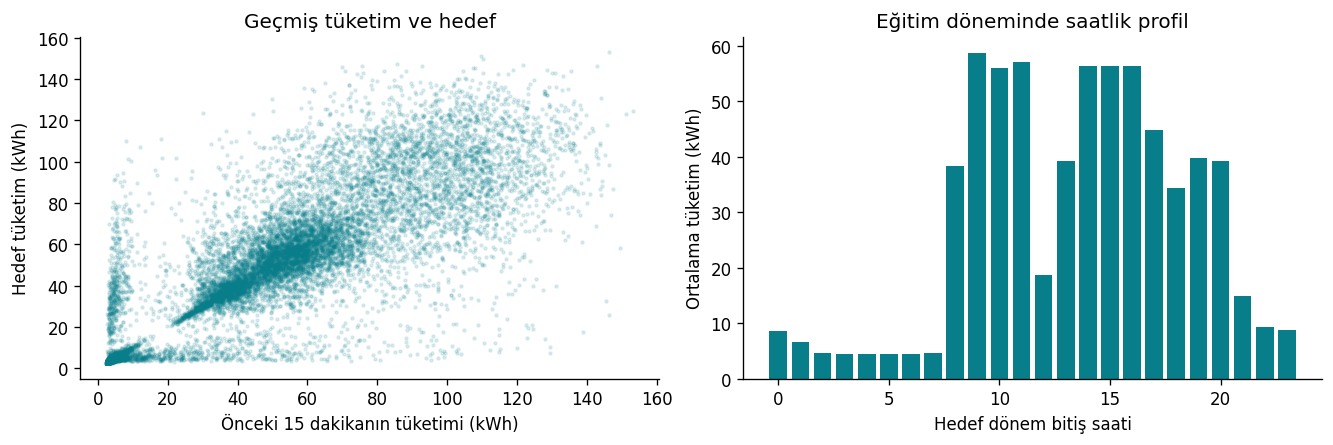

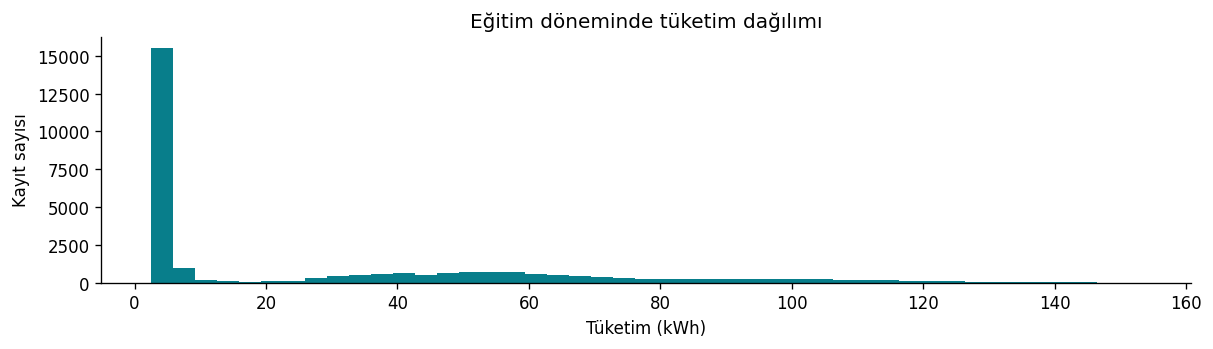

In [4]:
train = data.loc[X_train.index].copy()
display(train.groupby('hafta_sonu').Usage_kWh.agg(['count','mean','median','max']))
display(train.groupby(train.zaman.dt.hour).Usage_kWh.mean().to_frame('Ortalama_kWh'))
fig,axs=plt.subplots(1,2,figsize=(11,3.6),layout='constrained')
axs[0].scatter(train.tuketim_15dk_once,train.Usage_kWh,s=3,alpha=.12)
axs[0].set(xlabel='Önceki 15 dakikanın tüketimi (kWh)',ylabel='Hedef tüketim (kWh)',title='Geçmiş tüketim ve hedef')
hourly=train.groupby(train.zaman.dt.hour).Usage_kWh.mean()
axs[1].bar(hourly.index,hourly.values)
axs[1].set(xlabel='Hedef dönem bitiş saati',ylabel='Ortalama tüketim (kWh)',title='Eğitim döneminde saatlik profil')
plt.show()
fig,ax=plt.subplots(figsize=(10,2.8),layout='constrained')
ax.hist(train.Usage_kWh,bins=45)
ax.set(xlabel='Tüketim (kWh)',ylabel='Kayıt sayısı',title='Eğitim döneminde tüketim dağılımı')
plt.show()
print('Önceki tüketim ile hedef korelasyonu:',train.tuketim_15dk_once.corr(train.Usage_kWh).round(3))


**Keşif bulguları:**
- Önceki tüketimle hedef arasında güçlü pozitif ilişki vardır, bu nedenle gecikmeli değerler anlamlı aday girdilerdir.
- Noktaların köşegenden uzaklaşması ani tüketim değişimlerini gösterir. Son değeri tekrar eden tahmin bu noktalarda zorlanabilir.
- Saatlik ortalamalar gün içindeki faaliyet düzeyinin değiştiğini gösterir. Saat özelliği bu örüntüyü kısmen temsil eder.
- Düşük tüketimli kayıtların yoğunluğu, tek bir ortalama hatanın bütün çalışma koşullarını açıklayamayacağını gösterir.

## 5. Model eğitimi ve karşılaştırma
Yönergede önerilen **LinearRegression** kullanılıyor. Sürekli sayısal hedefe uygundur ve katsayıları incelenebilir. Varsayılan en küçük kareler çözümü (`fit_intercept=True`) kullanılır. Test verisiyle hiperparametre ayarı yapılmaz. Karşılaştırma modeli, bir önceki tüketimi tahmin olarak alır.


In [5]:
model=LinearRegression()
model.fit(X_train,y_train)
pred_train=model.predict(X_train)
pred_test=model.predict(X_test)
baseline=X_test.tuketim_15dk_once.to_numpy()
def metrics(actual,pred):
    return {'MAE (kWh)':mean_absolute_error(actual,pred),
            'RMSE (kWh)':np.sqrt(mean_squared_error(actual,pred)),
            'R²':r2_score(actual,pred)}
scores=pd.DataFrame({'Lineer / Eğitim':metrics(y_train,pred_train),
                     'Lineer / Test':metrics(y_test,pred_test),
                     'Son değer / Test':metrics(y_test,baseline)}).T
display(scores.round(4))
display(pd.Series(model.coef_,index=features,name='Katsayı').to_frame())
print('Sabit terim:',model.intercept_)
print('Negatif ham test tahmini:',int((pred_test<0).sum()))


Sabit terim: 3.1210539898220055
Negatif ham test tahmini: 0


,MAE (kWh),RMSE (kWh),R²
Lineer / Eğitim,7.4863,13.9551,0.8308
Lineer / Test,6.4522,12.0609,0.8522
Son değer / Test,5.4446,12.3245,0.8457


,Katsayı
tuketim_15dk_once,0.900289
tuketim_30dk_once,0.069999
son_1saat_ortalama,-0.073126
saat,0.034456
hafta_sonu,-2.333700


## 6. Sonuçların yorumu ve hata analizi
**R² bir doğruluk yüzdesi değildir.** Testte varyansın hangi bölümünün ortalama tahmine göre açıklandığını gösterir. MAE ortalama mutlak sapmayı, RMSE büyük hatalara daha fazla ağırlık veren sapmayı ölçer.

Lineer model test RMSE'sini basit son değer tahminine göre bir miktar düşürür. Ancak basit tahminin MAE'si daha iyidir. Bu nedenle modelin her açıdan üstün olduğu veya üretime hazır olduğu söylenemez. Eğitim ve test başarısının yakın olması tek başına aşırı öğrenme olmadığını kanıtlamaz. Tek bir zaman bölmesi kullanıldığı için farklı aylarda ayrıca doğrulama gerekir.


Baz modele göre MAE iyileşmesi: %-18.51; RMSE iyileşmesi: %2.14


,zaman,gercek_kWh,tahmin_kWh,son_deger_kWh,mutlak_hata_kWh
33360,2018-12-14 12:15:00,13.61,120.383846,132.01,106.773846
28272,2018-10-22 12:15:00,5.44,104.658325,112.61,99.218325
31152,2018-11-21 12:15:00,7.60,101.068349,109.33,93.468349
31728,2018-11-27 12:15:00,7.81,100.784201,108.61,92.974201
30576,2018-11-15 12:15:00,4.46,91.221389,97.24,86.761389


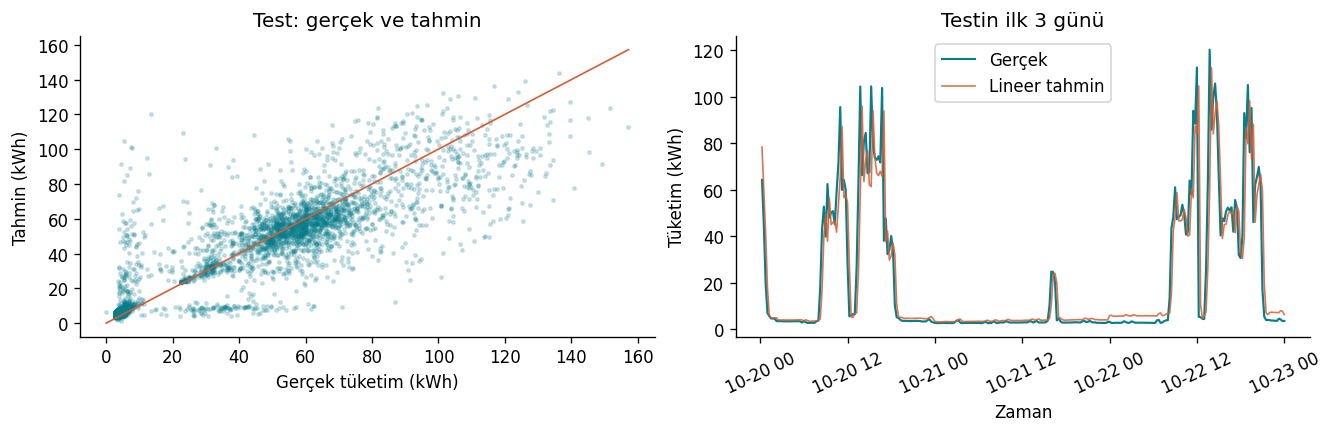

In [6]:
result=pd.DataFrame({'zaman':data.loc[X_test.index,'zaman'],
    'gercek_kWh':y_test,'tahmin_kWh':pred_test,'son_deger_kWh':baseline})
result['mutlak_hata_kWh']=(result.gercek_kWh-result.tahmin_kWh).abs()
display(result.nlargest(5,'mutlak_hata_kWh'))
fig,axs=plt.subplots(1,2,figsize=(11,3.5),layout='constrained')
axs[0].scatter(y_test,pred_test,s=4,alpha=.18)
lim=max(y_test.max(),pred_test.max());axs[0].plot([0,lim],[0,lim],color='#D45D35',lw=1)
axs[0].set(xlabel='Gerçek tüketim (kWh)',ylabel='Tahmin (kWh)',title='Test: gerçek ve tahmin')
sample=result.iloc[:96*3]
axs[1].plot(sample.zaman,sample.gercek_kWh,label='Gerçek',lw=1.3)
axs[1].plot(sample.zaman,sample.tahmin_kWh,label='Lineer tahmin',lw=1,alpha=.85)
axs[1].set(xlabel='Zaman',ylabel='Tüketim (kWh)',title='Testin ilk 3 günü');axs[1].legend();axs[1].tick_params(axis='x',rotation=25)
plt.show()
mae_gain=(1-scores.loc['Lineer / Test','MAE (kWh)']/scores.loc['Son değer / Test','MAE (kWh)'])*100
rmse_gain=(1-scores.loc['Lineer / Test','RMSE (kWh)']/scores.loc['Son değer / Test','RMSE (kWh)'])*100
print(f'Baz modele göre MAE iyileşmesi: %{mae_gain:.2f}; RMSE iyileşmesi: %{rmse_gain:.2f}')


**Sınırlılıklar ve geliştirme:** Ani başlatma/durdurma hareketlerinde geçmiş tüketim yeterli olmayabilir. Üretim programı ve makine durumları veri setinde yoktur. Tek tesis ve tek yıl, başka tesislere genellemeyi sınırlar. Sonraki çalışmada ileri zamanlı doğrulama ve yalnızca tahmin anında bilinen üretim programı girdileri denenebilir. Modelin fiziksel sınırları garanti eden bir kısıtı yoktur, negatif tahminleri ayrıca izlemek gerekir. Bu projede test metrikleri ham tahminlerden hesaplanır.

## 7. Yeni örnekler ve mini uygulama
Aşağıdaki üç senaryo **temsili girdilerdir**, doğrulanmış gelecek gözlemleri değildir. Bu nedenle bu senaryolar için tahmin doğruluğu hesaplanmaz. Girdiler kWh cinsindedir. Bir saatlik ortalama, önceki dört 15 dakikalık tüketimin aritmetik ortalamasıdır.


In [7]:
def tahmin_et(tuketim_15dk_once,tuketim_30dk_once,son_1saat_ortalama,saat,hafta_sonu):
    values=np.asarray([tuketim_15dk_once,tuketim_30dk_once,son_1saat_ortalama,saat,hafta_sonu],dtype=float)
    if not np.isfinite(values).all(): raise ValueError('Girdiler sonlu sayılar olmalı.')
    if (values[:3]<0).any(): raise ValueError('Tüketim negatif olamaz.')
    if not 0<=saat<24: raise ValueError('Saat 0 dahil, 24 hariç aralıkta olmalı.')
    if hafta_sonu not in (0,1): raise ValueError('Hafta sonu 0 veya 1 olmalı.')
    # Ortalama ilk iki geçmiş değeri de içerir. Kalan iki değer negatif olamaz.
    if 4*son_1saat_ortalama+1e-9 < tuketim_15dk_once+tuketim_30dk_once:
        raise ValueError('Bir saatlik ortalama geçmiş tüketimlerle tutarsız.')
    return float(model.predict(pd.DataFrame([values],columns=features))[0])
scenarios=pd.DataFrame([[3.5,3.8,3.6,2,0],[55,52,50,10.25,0],[8,9,8.5,14,1]],columns=features)
scenarios['tahmin_kWh']=[tahmin_et(*row) for row in scenarios.to_numpy()]
display(scenarios.round(3))
def tahmin_araci():
    try:
        labels=['Önceki 15 dakika (kWh): ','Önceki 30 dakika (kWh): ',
                'Önceki dört dönemin ortalaması (kWh): ',
                'Hedef dönem bitiş saati (örn. 10.25): ','Hafta sonu mu? (1=Evet, 0=Hayır): ']
        vals=[float(input(label).replace(',','.')) for label in labels]
        prediction=tahmin_et(*vals)
        if prediction<0:
            print(f'Model fiziksel açıdan geçersiz bir tahmin üretti ({prediction:.3f} kWh). Girdileri kontrol edin.')
        else:
            print(f'Bir sonraki 15 dakikalık dönem için tahmini tüketim: {prediction:.3f} kWh.')
    except ValueError as e:
        print('Girdi hatası:',e)


,tuketim_15dk_once,tuketim_30dk_once,son_1saat_ortalama,saat,hafta_sonu,tahmin_kWh
0,3.5,3.8,3.6,2.00,0,6.344
1,55.0,52.0,50.0,10.25,0,52.974
2,8.0,9.0,8.5,14.00,1,8.480


## 8. Teslim ve kullanım
Bu defter düzenli kod, veri sözlüğü, temizlik kontrolleri, etiketli grafikler, eğitim/test boyutları, metrikler ve üç yeni senaryo içerir. Rapor ve sunum bu çalıştırmanın sonuçlarını kullanır.

**Colab bağlantısı:** Defteri kendi Google hesabınızda açıp Drive'a kaydedin. Paylaşım menüsünden değerlendiricinin açabileceği görüntüleme erişimini seçin ve oluşan bağlantıyı teslim formuna yapıştırın. Yerel `.ipynb` dosyası kendiliğinden bir Colab paylaşım bağlantısı oluşturmaz.

**Mini uygulama:** Sonraki hücreyi çalıştırın. Beş soruya cevap verin. Her cevap sonrası Enter'a basın. Yeni bir tahmin için aynı hücreyi tekrar çalıştırın. Ondalık sayılarda nokta veya virgül kullanılabilir.


In [ ]:
tahmin_araci()